In [1]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
try:
    from IPython.display import display
except ImportError:
    display = print

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

DATA_PATH = 'Dataset/Titanic-Dataset.csv'
if not os.path.exists(DATA_PATH):
    os.makedirs('Dataset', exist_ok=True)
    urllib.request.urlretrieve('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv', DATA_PATH)

df = pd.read_csv(DATA_PATH)
print('Dataset loaded successfully. Shape:', df.shape)


Dataset loaded successfully. Shape: (891, 12)


In [2]:
print('Dataset Shape:', df.shape)
print('\nColumn Data Types:')
print(df.dtypes)
print('\nFirst 5 Rows:')
display(df.head())
print('\nSummary Statistics:')
display(df.describe())
print('\nMissing Values per Column:')
missing_df = pd.DataFrame({'Missing': df.isnull().sum(), 'Percent(%)': (df.isnull().sum() / len(df) * 100).round(2)}).sort_values(by='Missing', ascending=False)
display(missing_df)


Dataset Shape: (891, 12)

Column Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Missing Values per Column:
             Missing  Percent(%)
Cabin            687       77.10
Age              177       19.87
Embarked           2        0.22
PassengerId        0        0.00
Survived           0        0.00
Pclass             0        0.00
Name               0        0.00
Sex                0        0.00
SibSp              0        0.00
Parch              0        0.00
Ticket             0        0.00
Fare               0        0.00


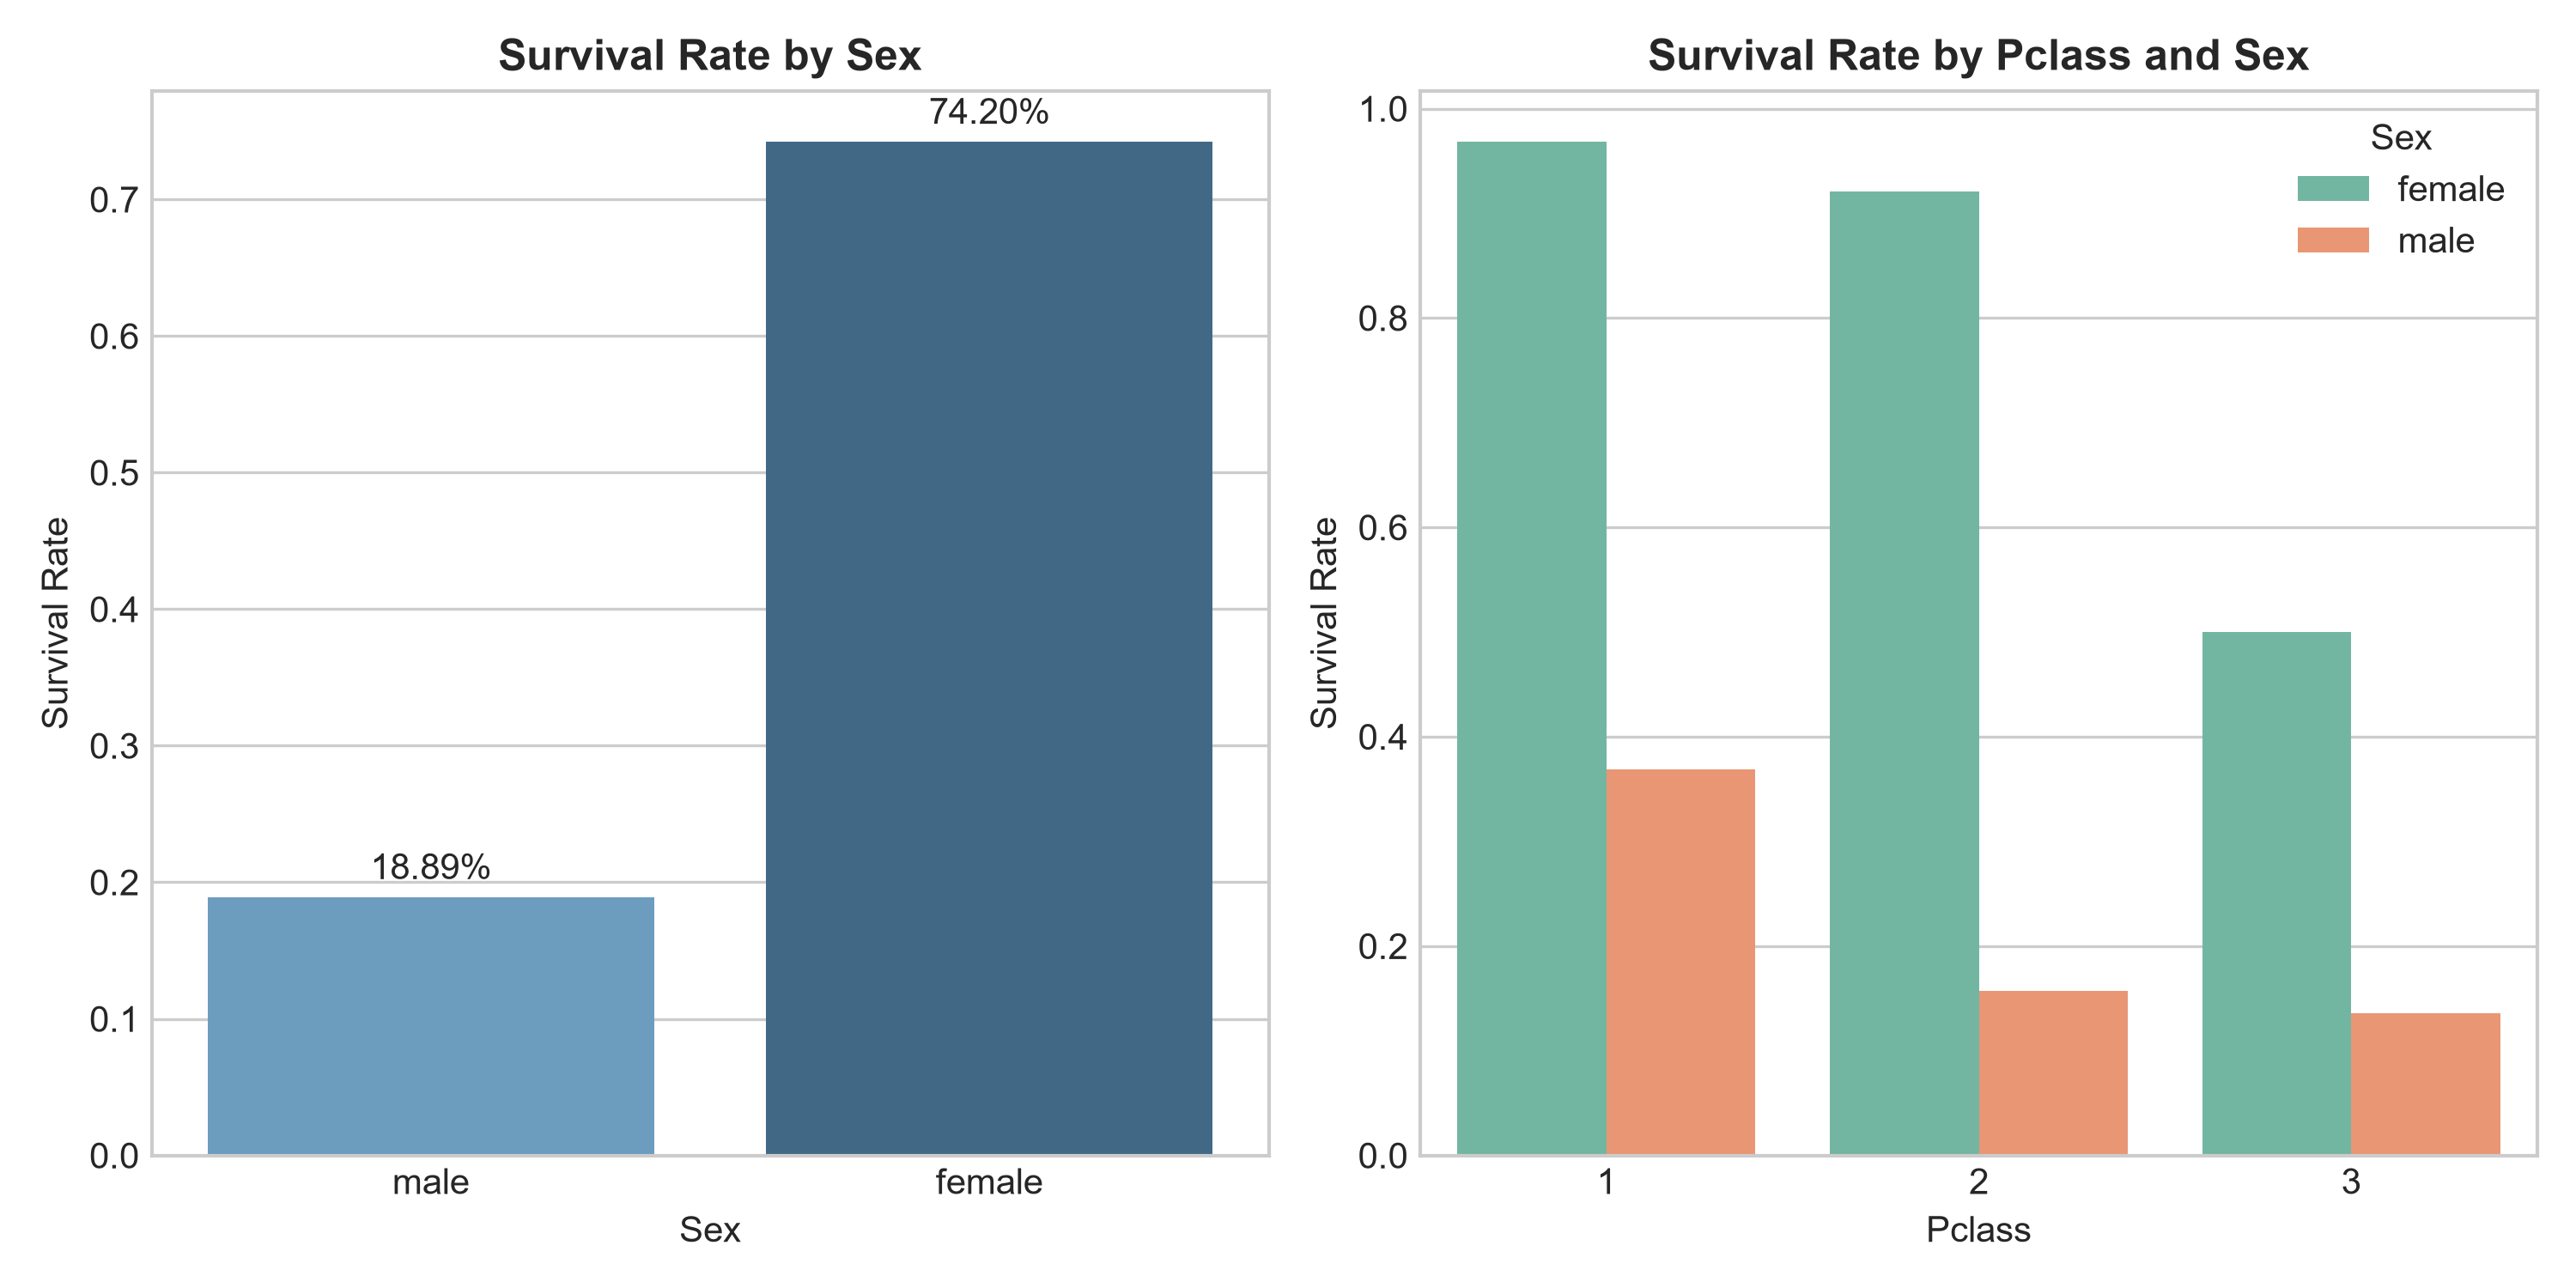

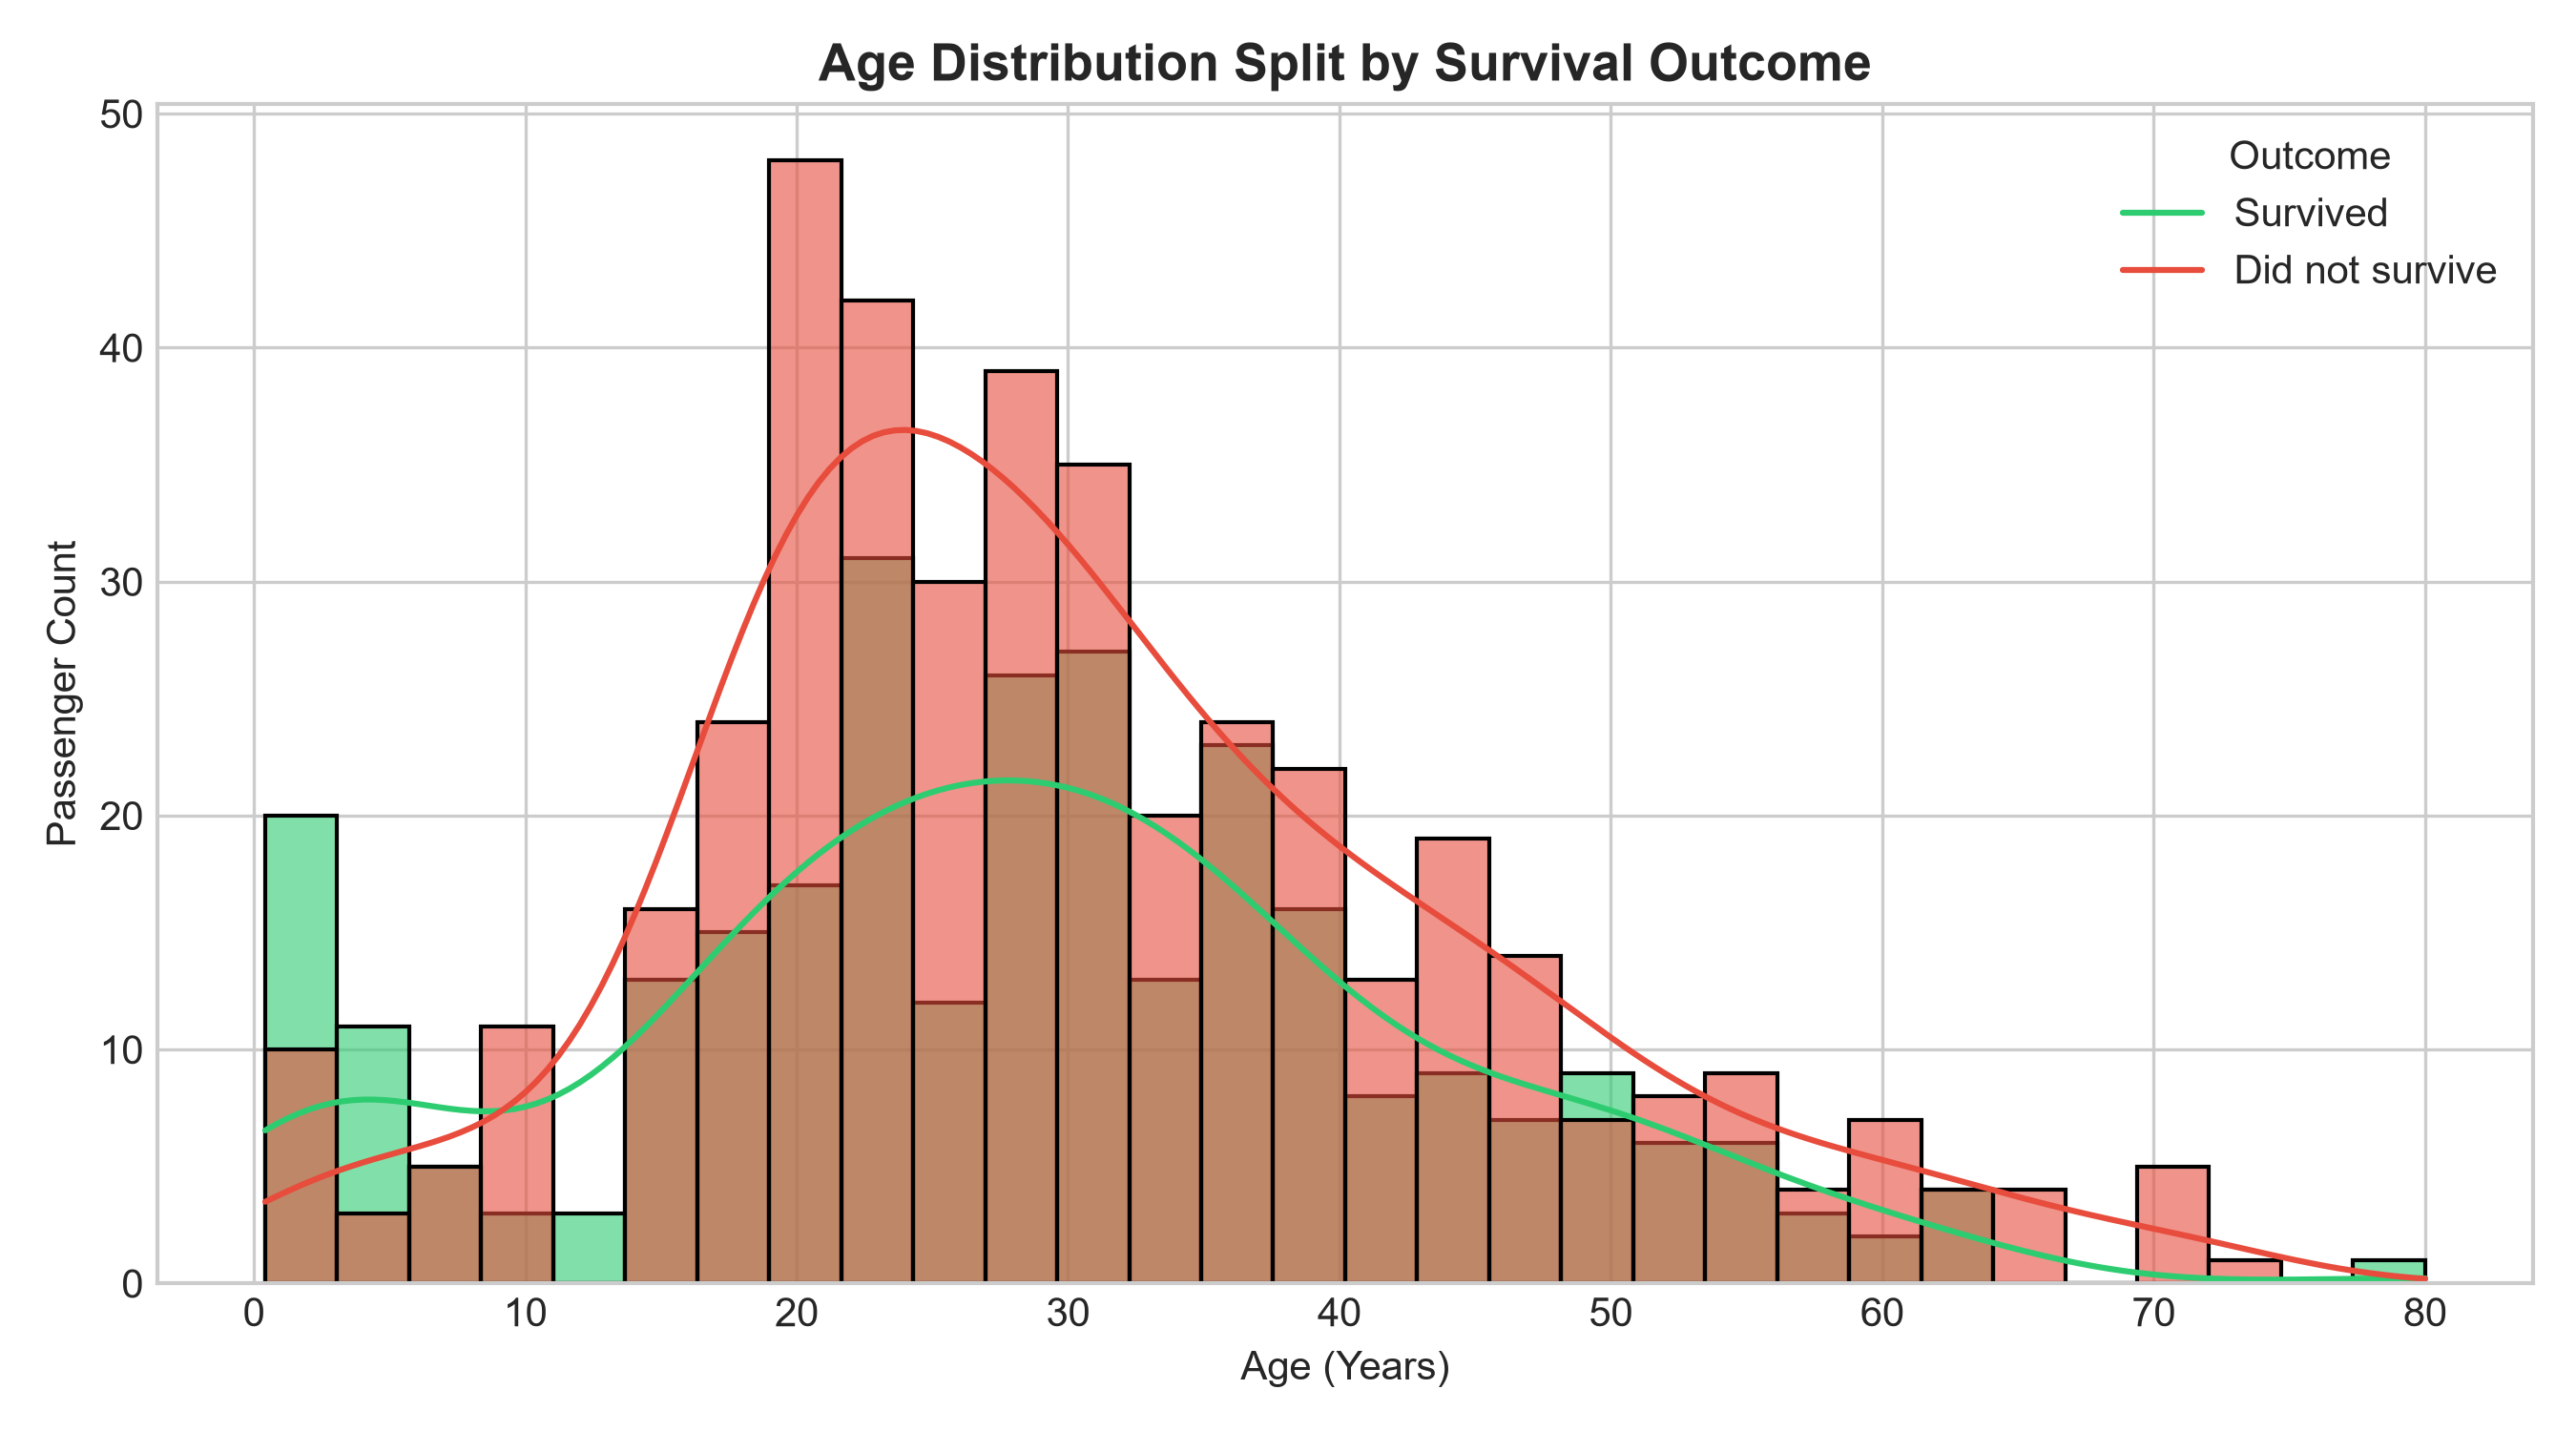

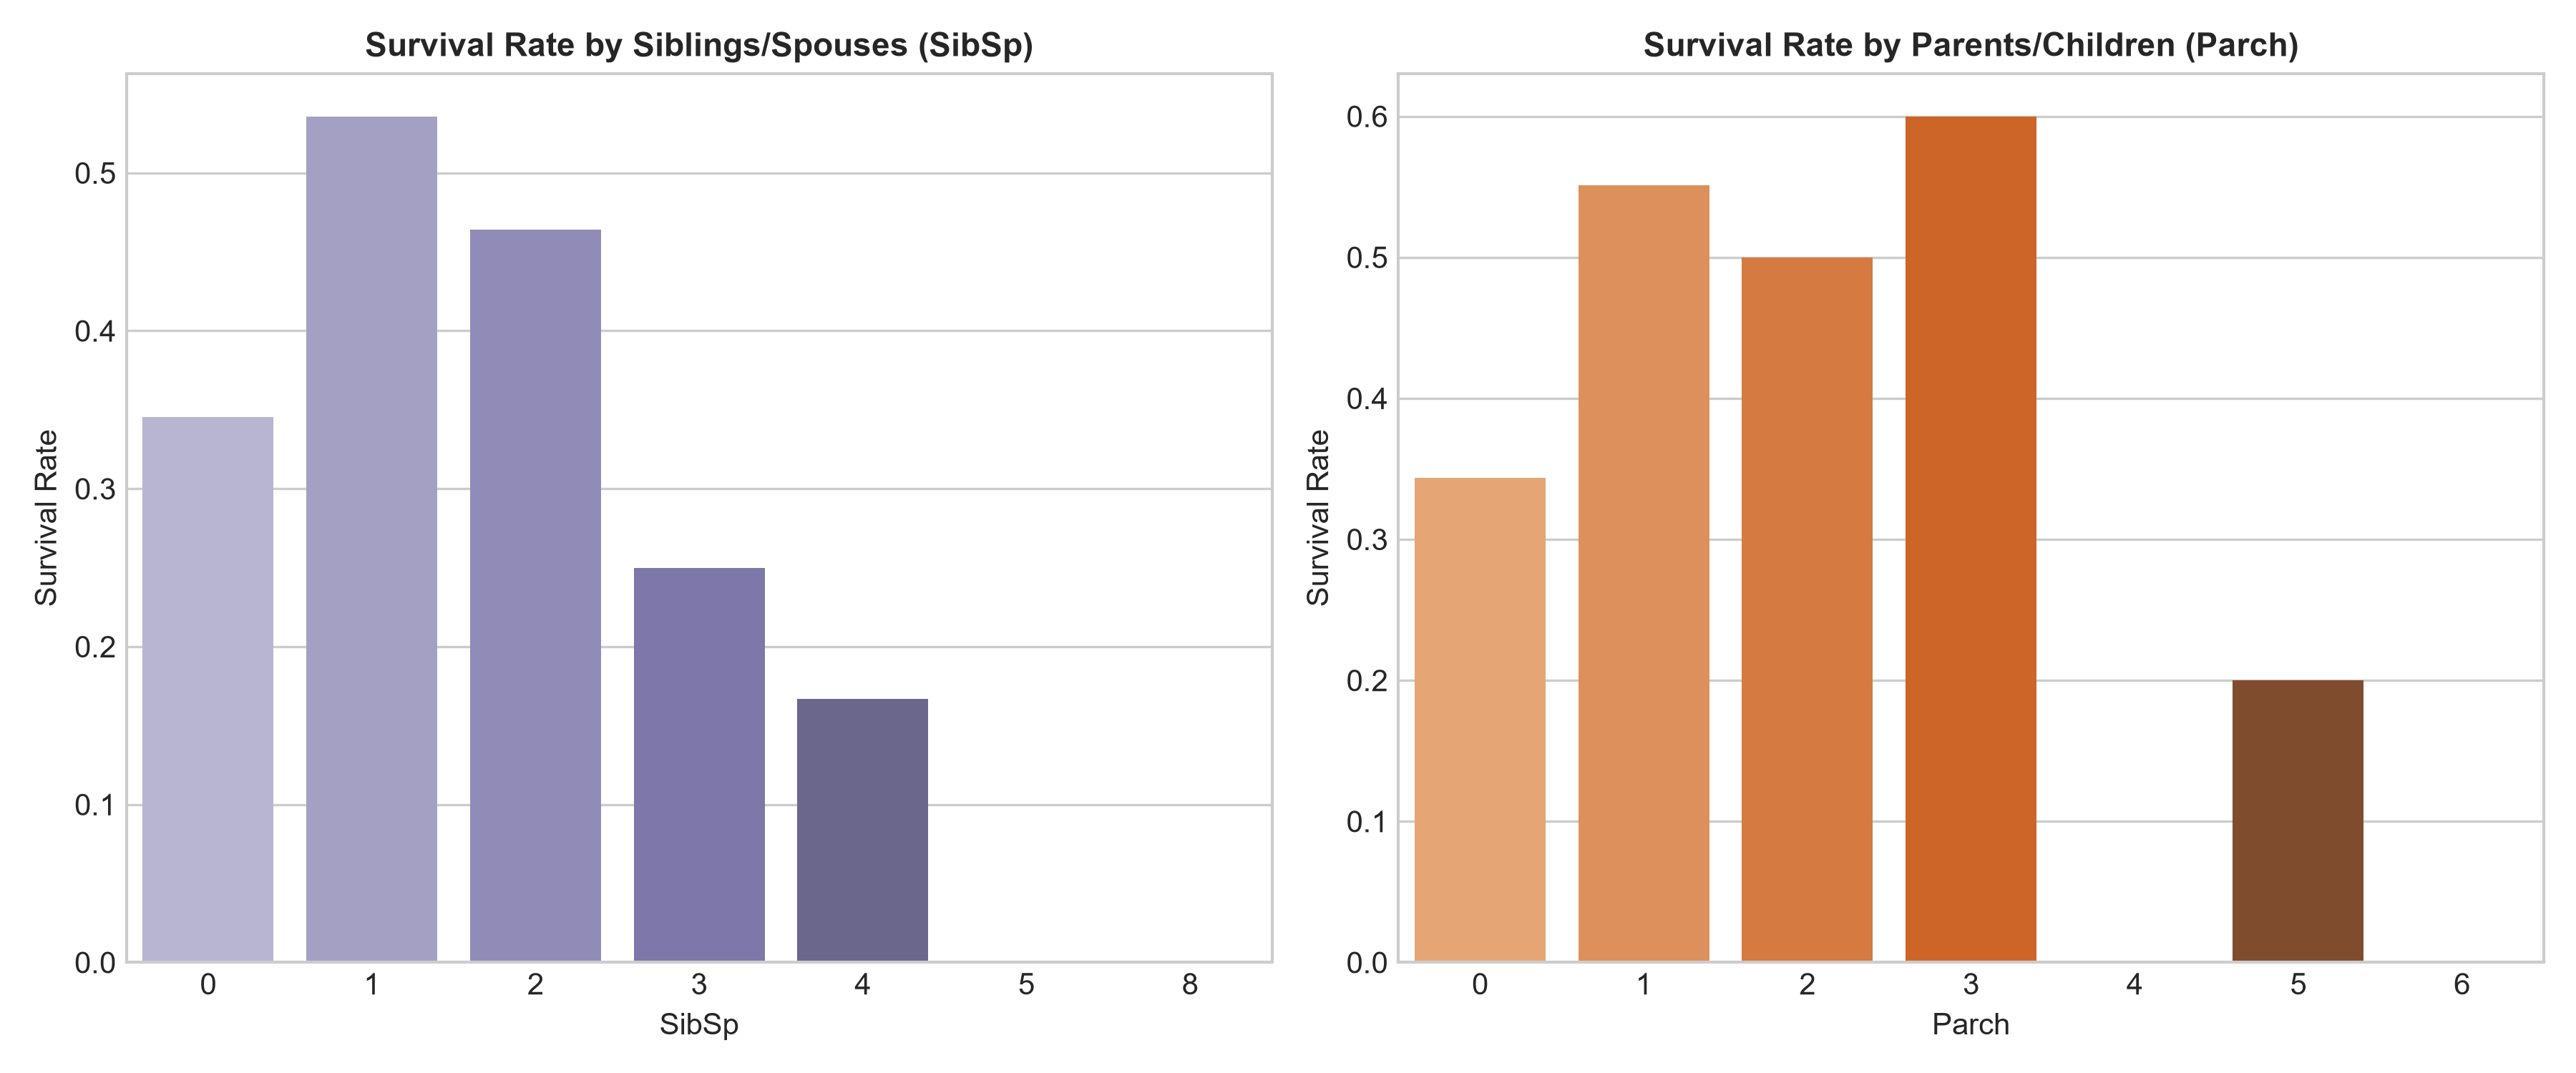

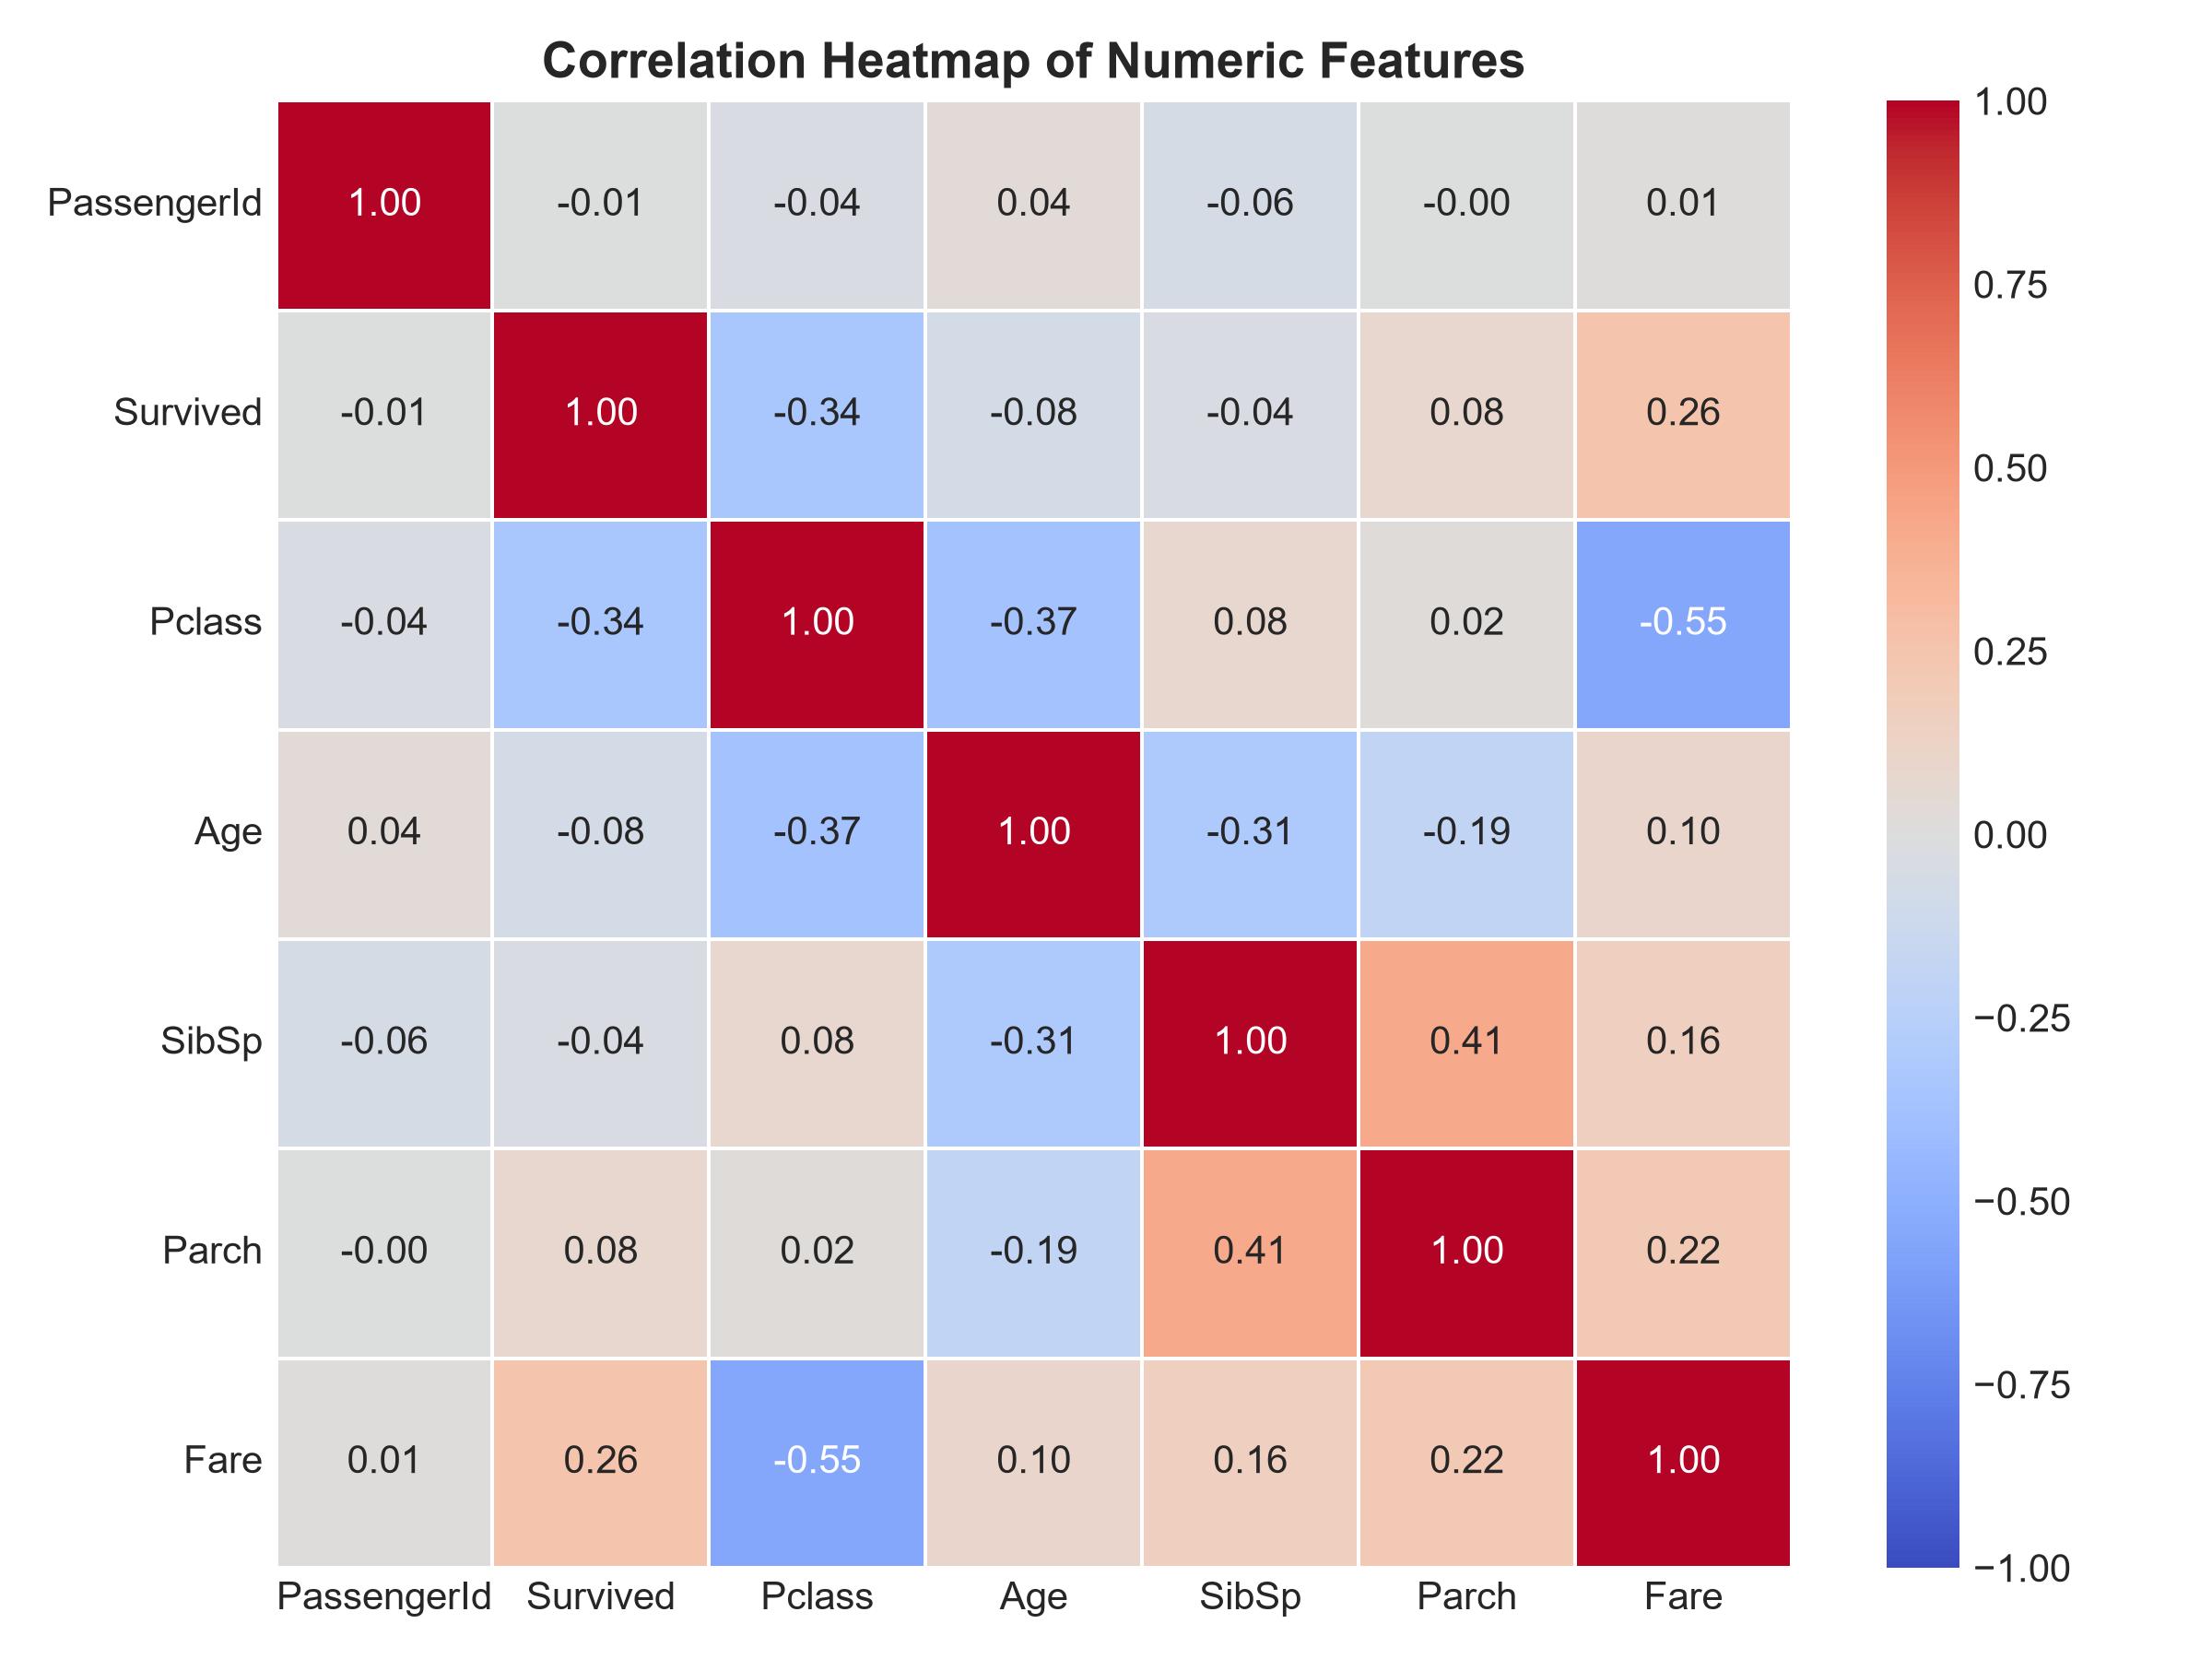

In [3]:
# 1. Survival Rate by Sex and Pclass
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.barplot(ax=axes[0], x='Sex', y='Survived', data=df, errorbar=None, palette='Blues_d')
axes[0].set_title('Survival Rate by Sex')
axes[0].set_ylabel('Survival Rate')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')
sns.barplot(ax=axes[1], x='Pclass', y='Survived', hue='Sex', data=df, errorbar=None, palette='Set2')
axes[1].set_title('Survival Rate by Pclass and Sex')
axes[1].set_ylabel('Survival Rate')
plt.tight_layout()
plt.show()

# 2. Age Distribution Split by Survival Outcome
plt.figure(figsize=(9, 4.5))
sns.histplot(data=df, x='Age', hue='Survived', kde=True, bins=30, palette={0: '#e74c3c', 1: '#2ecc71'}, alpha=0.6)
plt.title('Age Distribution by Survival Outcome')
plt.xlabel('Age')
plt.ylabel('Passenger Count')
plt.tight_layout()
plt.show()

# 3. Survival Analysis by Family Travel (SibSp and Parch)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.barplot(ax=axes[0], x='SibSp', y='Survived', data=df, errorbar=None, palette='Purples_d')
axes[0].set_title('Survival Rate by SibSp')
axes[0].set_ylabel('Survival Rate')
sns.barplot(ax=axes[1], x='Parch', y='Survived', data=df, errorbar=None, palette='Oranges_d')
axes[1].set_title('Survival Rate by Parch')
axes[1].set_ylabel('Survival Rate')
plt.tight_layout()
plt.show()

# 4. Correlation Heatmap of Numeric Features
plt.figure(figsize=(7, 5))
numeric_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()


In [4]:
df_clean = df.copy()

# Extract honorific Title
df_clean['Title'] = df_clean['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
rare_titles = ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df_clean['Title'] = df_clean['Title'].replace(rare_titles, 'Rare')
df_clean['Title'] = df_clean['Title'].replace(['Mlle', 'Ms'], 'Miss')
df_clean['Title'] = df_clean['Title'].replace('Mme', 'Mrs')

# Impute missing Age (grouped median by Pclass and Sex)
df_clean['Age'] = df_clean.groupby(['Pclass', 'Sex'])['Age'].transform(lambda s: s.fillna(s.median()))

# Impute missing Embarked with mode
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

# Feature Engineering: has_cabin, family_size, is_alone
df_clean['has_cabin'] = df_clean['Cabin'].notna().astype(int)
df_clean['family_size'] = df_clean['SibSp'] + df_clean['Parch'] + 1
df_clean['is_alone'] = (df_clean['family_size'] == 1).astype(int)

# Drop non-predictive identifiers & One-Hot Encode
df_model = df_clean.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
df_model = pd.get_dummies(df_model, columns=['Sex', 'Embarked', 'Title'], drop_first=True, dtype=int)

print('Engineered Dataset Shape:', df_model.shape)
print('Remaining Missing Values:', df_model.isnull().sum().sum())
display(df_model.head())


Engineered Dataset Shape: (891, 16)
Remaining Missing Values: 0


In [5]:
X = df_model.drop(columns=['Survived'])
y = df_model['Survived']

# Stratified 80/20 Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Standardize numeric continuous features
scale_cols = ['Age', 'Fare', 'family_size']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

# Train Logistic Regression
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print('X_train Shape:', X_train.shape)
print('X_test Shape: ', X_test.shape)
print('Logistic Regression Model trained successfully.')


X_train Shape: (712, 15)
X_test Shape:  (179, 15)
Logistic Regression Model trained successfully.


EVALUATION METRICS (TEST SET)
Accuracy:  0.8212 (82.12%)
Precision: 0.7937 (79.37%)
Recall:    0.7246 (72.46%)
F1 Score:  0.7576 (75.76%)

Classification Report:
              precision    recall  f1-score   support

Perished (0)       0.84      0.88      0.86       110
Survived (1)       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



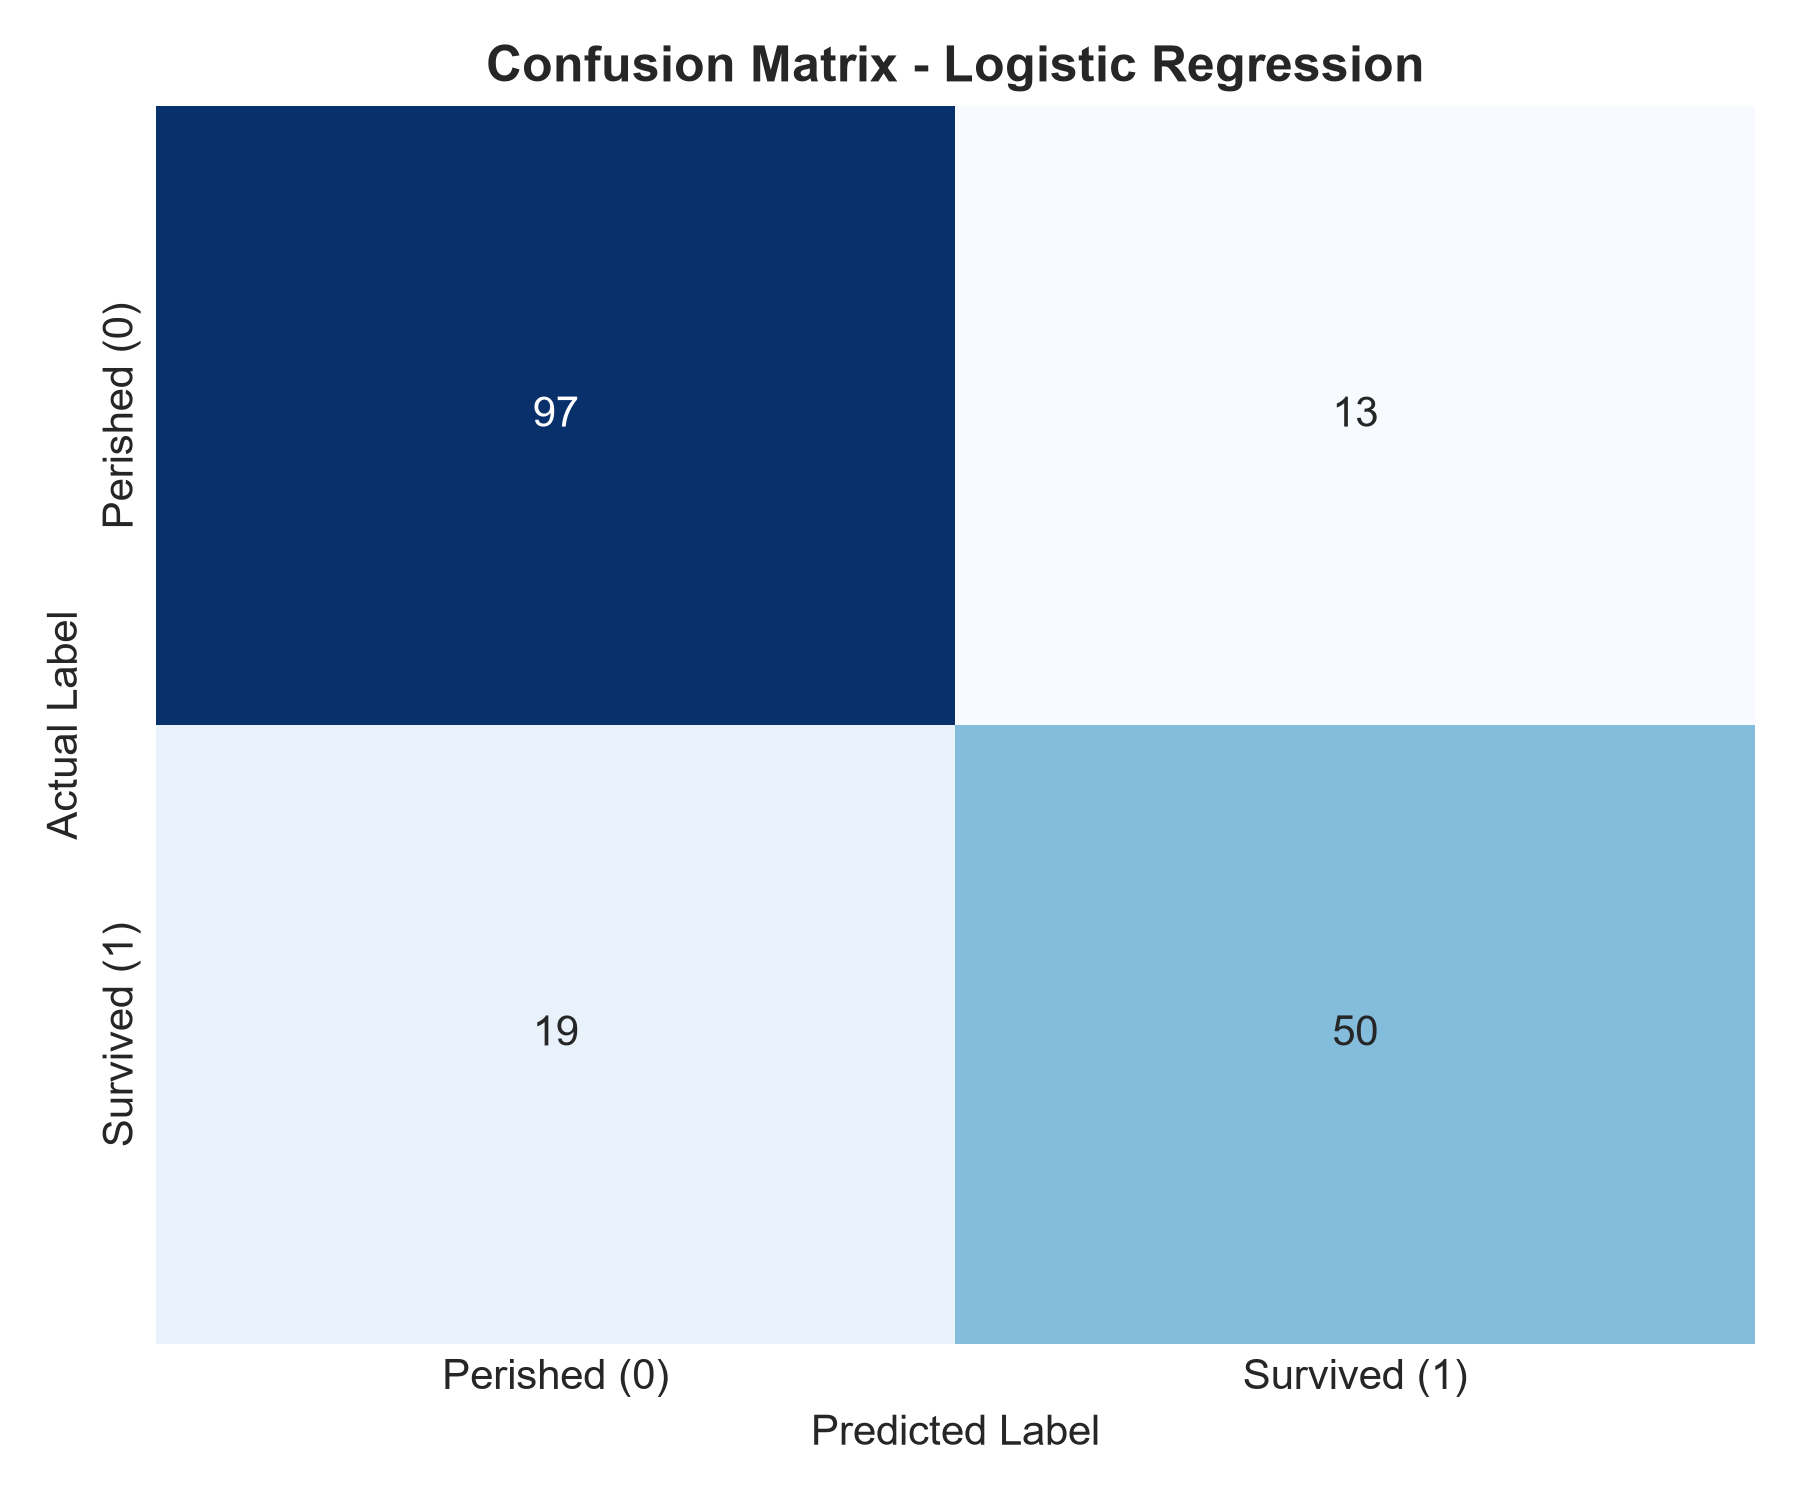

In [6]:
y_pred = model.predict(X_test_scaled)

print('='*50)
print('EVALUATION METRICS (TEST SET)')
print('='*50)
print(f'Accuracy:  {accuracy_score(y_test, y_pred):.4f} ({accuracy_score(y_test, y_pred):.2%})')
print(f'Precision: {precision_score(y_test, y_pred):.4f} ({precision_score(y_test, y_pred):.2%})')
print(f'Recall:    {recall_score(y_test, y_pred):.4f} ({recall_score(y_test, y_pred):.2%})')
print(f'F1 Score:  {f1_score(y_test, y_pred):.4f} ({f1_score(y_test, y_pred):.2%})')
print('='*50)

print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Perished (0)', 'Survived (1)']))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()


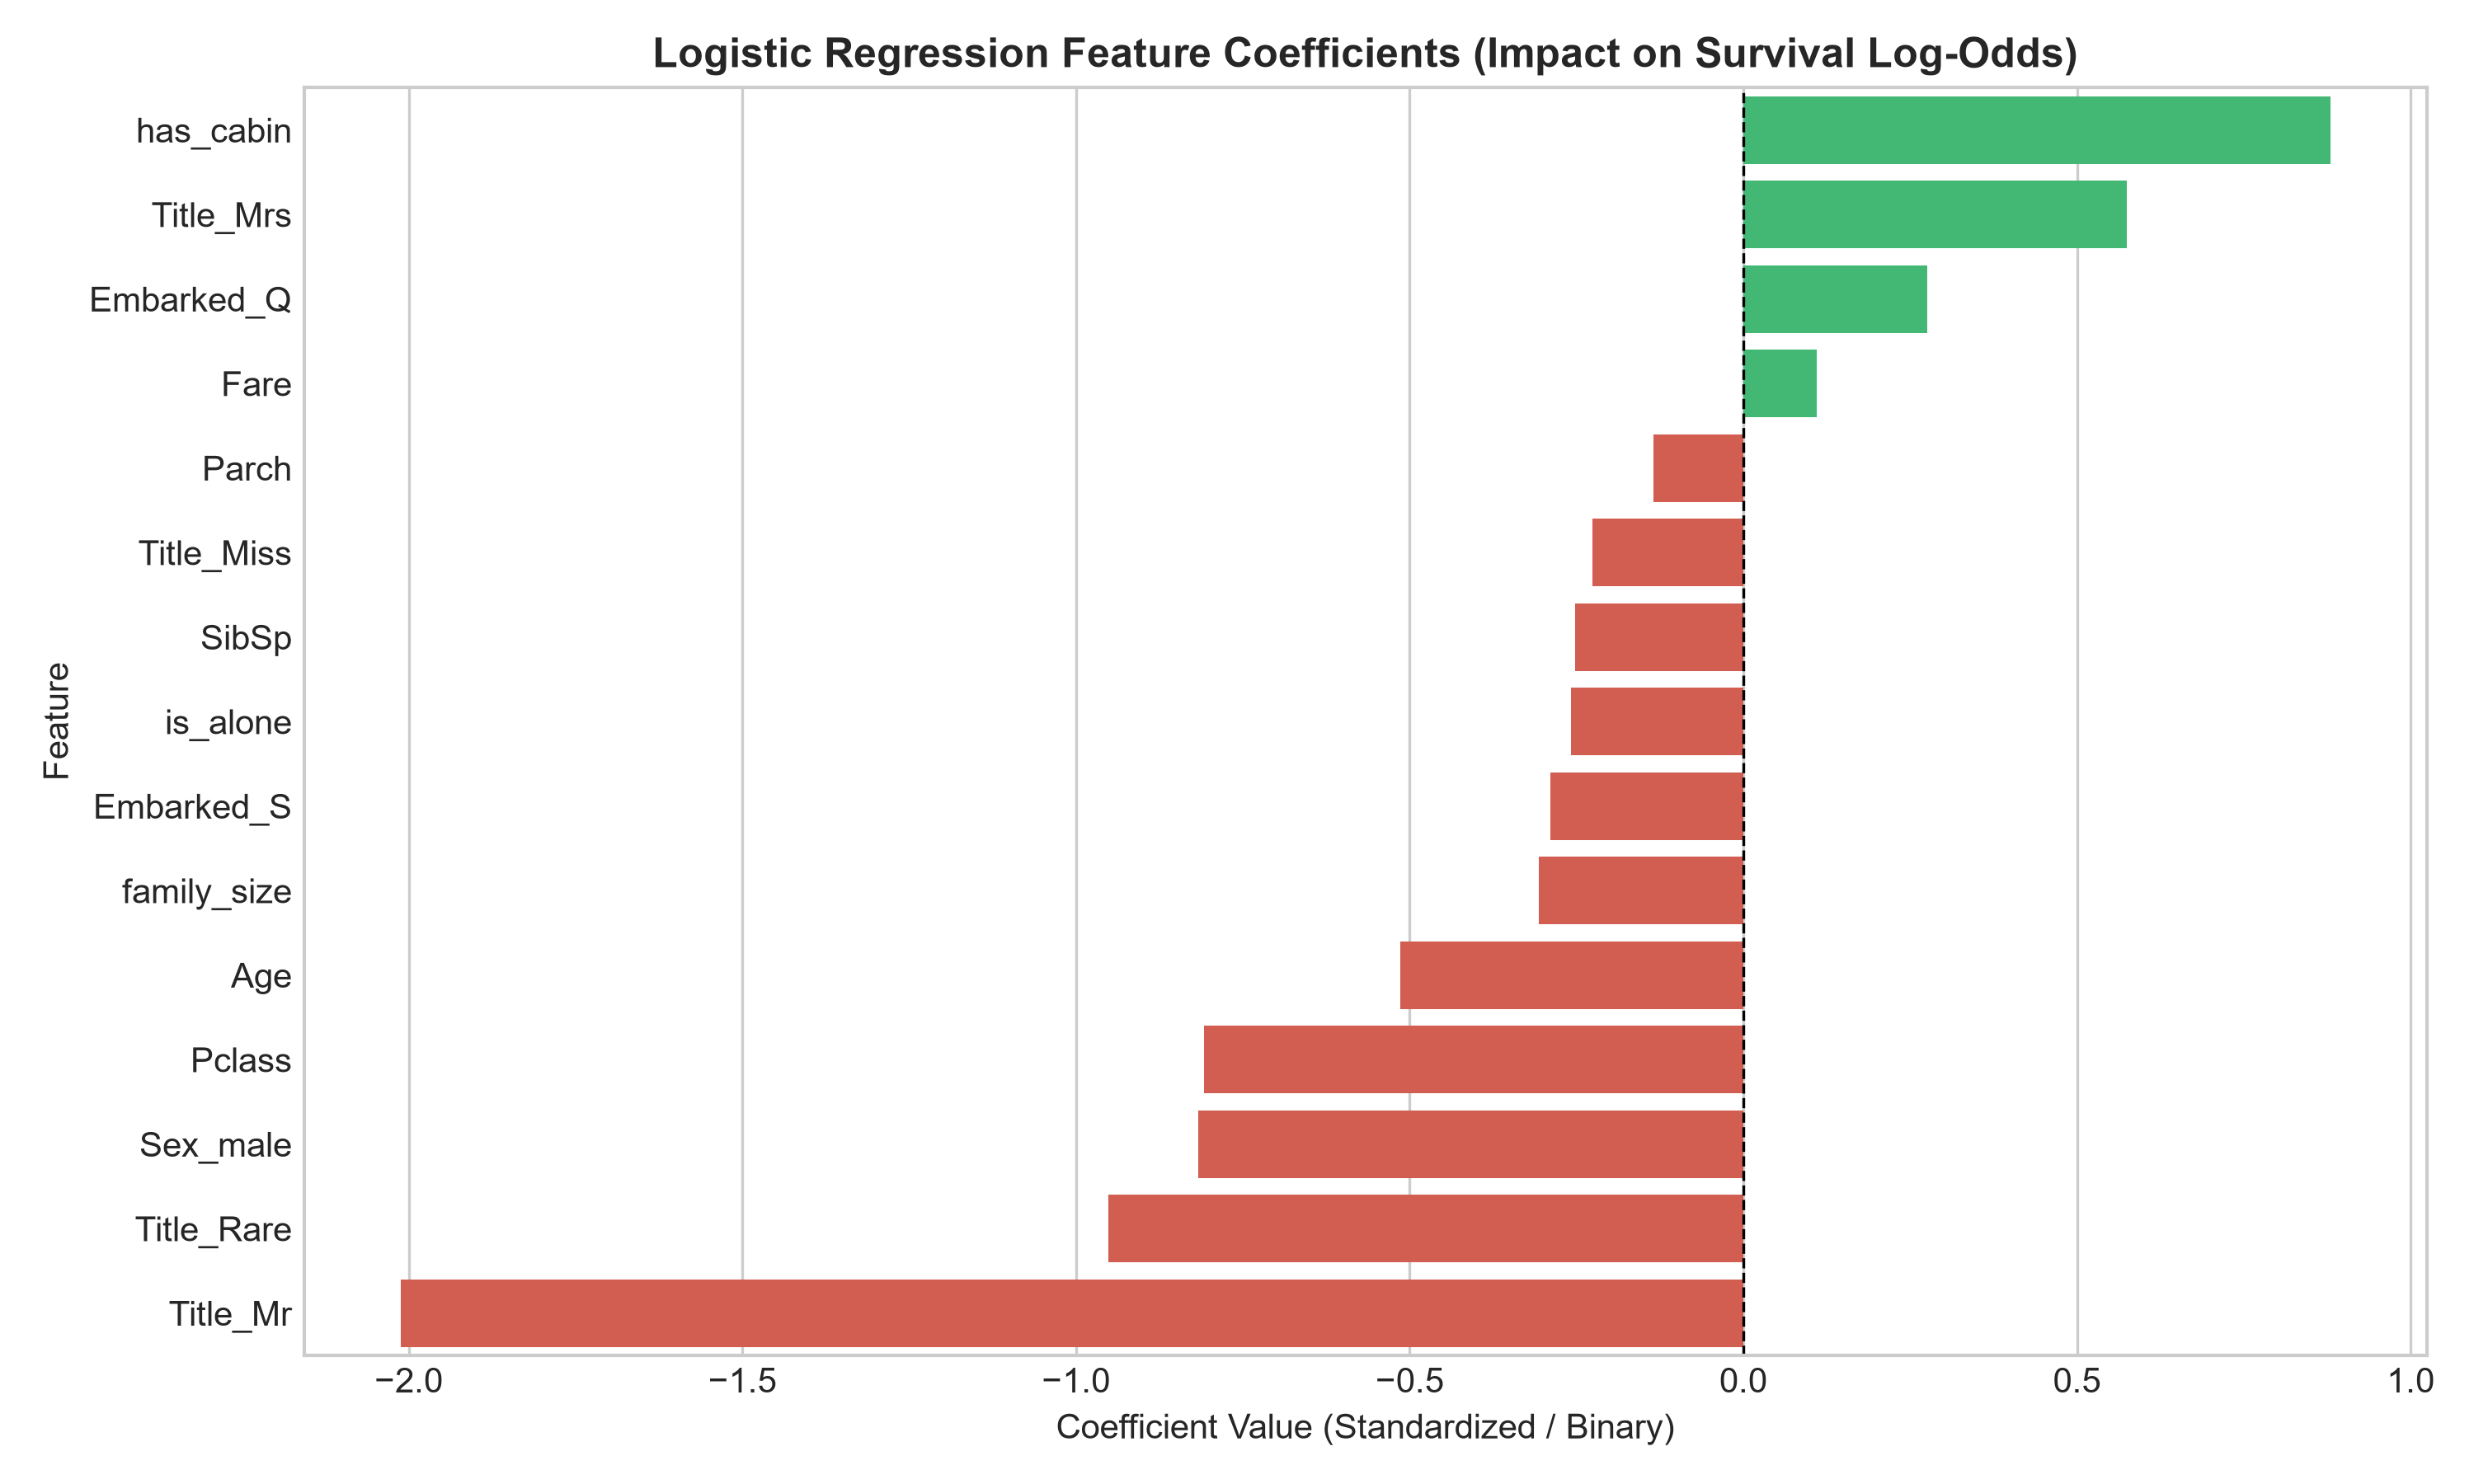

EXPLANATION OF KEY SURVIVAL FACTORS (ADDITIONAL REQUIREMENT)
1. Title_Mr (Coefficient: -2.0123, Odds Ratio: 0.1337):
   Adult civilian men had an 86.6% lower odds of surviving compared to baseline,
   directly proving the strict enforcement of the 'women and children first' maritime protocol.

2. has_cabin (Coefficient: +0.8796, Odds Ratio: 2.4099):
   Passengers with an assigned cabin had 2.41x higher survival odds, as first/second class
   cabins were situated on top decks with quick, direct stairway access to lifeboats.

3. Sex_male (Coefficient: -0.8164, Odds Ratio: 0.4420):
   Independent of title, biological male gender decreased survival odds by 55.8%.

4. Pclass (Coefficient: -0.8076, Odds Ratio: 0.4459):
   Each step downward in class (1st -> 2nd -> 3rd) decreased survival odds by 55.4%.
   Steerage (3rd class) passengers faced locked corridor gates and delayed evacuation access.

5. Title_Mrs (Coefficient: +0.5742, Odds Ratio: 1.7758):
   Married women had 77.6% higher surviv

In [7]:
# Extract coefficients and calculate odds ratios
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0],
    'Odds_Ratio': np.exp(model.coef_[0])
}).sort_values(by='Coefficient', ascending=False).reset_index(drop=True)
display(coef_df)

# Feature Importance Plot
plt.figure(figsize=(9, 5.5))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in coef_df['Coefficient']]
sns.barplot(x='Coefficient', y='Feature', data=coef_df, palette=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Logistic Regression Feature Coefficients (Impact on Survival Log-Odds)')
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

# Additional Requirement: Explanation of Key Survival Factors
print('='*70)
print('EXPLANATION OF KEY SURVIVAL FACTORS (ADDITIONAL REQUIREMENT)')
print('='*70)
print('1. Title_Mr (Coefficient: -2.0123, Odds Ratio: 0.1337):')
print("   Adult civilian men had an 86.6% lower odds of surviving compared to baseline,")
print("   directly proving the strict enforcement of the 'women and children first' maritime protocol.")
print('\n2. has_cabin (Coefficient: +0.8796, Odds Ratio: 2.4099):')
print('   Passengers with an assigned cabin had 2.41x higher survival odds, as first/second class')
print('   cabins were situated on top decks with quick, direct stairway access to lifeboats.')
print('\n3. Sex_male (Coefficient: -0.8164, Odds Ratio: 0.4420):')
print('   Independent of title, biological male gender decreased survival odds by 55.8%.')
print('\n4. Pclass (Coefficient: -0.8076, Odds Ratio: 0.4459):')
print('   Each step downward in class (1st -> 2nd -> 3rd) decreased survival odds by 55.4%.')
print('   Steerage (3rd class) passengers faced locked corridor gates and delayed evacuation access.')
print('\n5. Title_Mrs (Coefficient: +0.5742, Odds Ratio: 1.7758):')
print('   Married women had 77.6% higher survival odds, prioritizing families and mothers during evacuation.')
print('\n6. Age (Coefficient: -0.5134, Odds Ratio: 0.5985):')
print('   Older passengers had lower odds of survival compared to infants and young children.')
print('='*70)
